<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train shape: (6000, 784) | Test shape: (500, 784)

Initial Joint Energies E(v, h) for 5 test samples: [-0.597  0.491 -0.364 -0.48  -0.711] 

Epoch  1/20 | Avg Free Energy:   -38.28 | Recon MSE: 0.0971
Epoch  5/20 | Avg Free Energy:   -94.68 | Recon MSE: 0.0548
Epoch 10/20 | Avg Free Energy:  -128.91 | Recon MSE: 0.0463
Epoch 15/20 | Avg Free Energy:  -146.28 | Recon MSE: 0.0424
Epoch 20/20 | Avg Free Energy:  -162.19 | Recon MSE: 0.0403

Trained Joint Energies E(v, h) for 5 test samples: [-173.982 -130.211 -200.576 -161.991 -159.486]


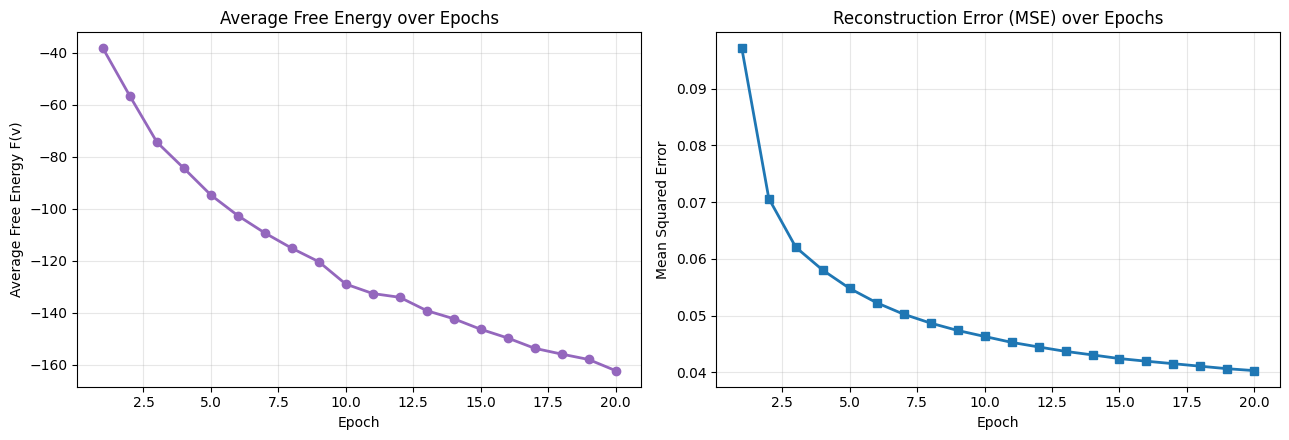

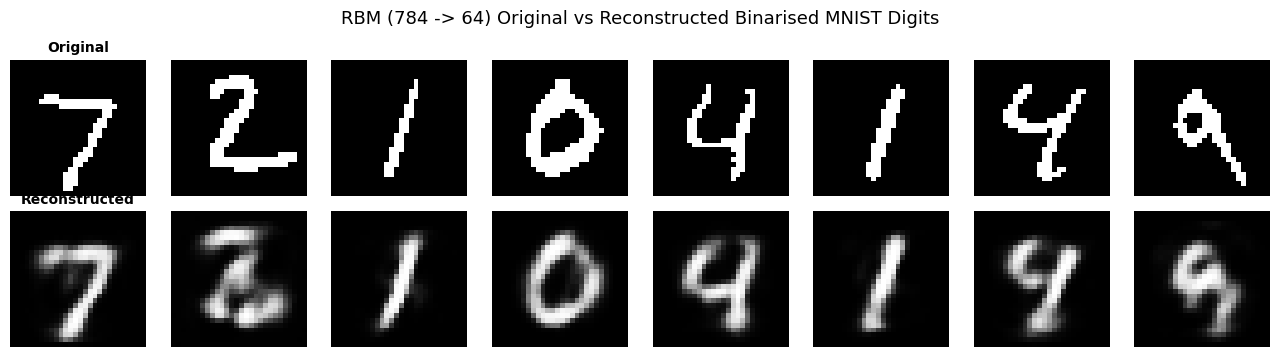

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit as sigmoid
from tensorflow.keras.datasets import mnist

# Reproducibility
np.random.seed(42)

# ==========================================
# Load & Binarise MNIST Dataset (784 Visible Units)
# ==========================================
(X_train_raw, _), (X_test_raw, _) = mnist.load_data()

# Flatten 28x28 -> 784 and binarise (> 0.5 -> 1, else 0)
X_train = (X_train_raw[:6000].reshape(-1, 784) / 255.0 > 0.5).astype(np.float32)
X_test  = (X_test_raw[:500].reshape(-1, 784) / 255.0 > 0.5).astype(np.float32)

print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}\n")

# ==========================================
# Task 1, 2 & 3: RBM Class (Energy, Probabilities, CD-1)
# ==========================================
class RBM:
    def __init__(self, n_visible=784, n_hidden=64, seed=42):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0.0, 0.01, size=(n_visible, n_hidden)).astype(np.float32)
        self.a = np.zeros(n_visible, dtype=np.float32)  # Visible biases
        self.b = np.zeros(n_hidden, dtype=np.float32)   # Hidden biases

    # Task 1a: Joint Energy E(v, h) = -a^T v - b^T h - v^T W h
    def energy(self, v, h):
        term_v = v @ self.a
        term_h = h @ self.b
        term_vh = np.sum((v @ self.W) * h, axis=1)
        return -(term_v + term_h + term_vh)

    # Task 1b: Free Energy F(v) = -a^T v - sum_j log(1 + exp(b_j + (vW)_j))
    def free_energy(self, v):
        wx_b = v @ self.W + self.b
        visible_term = v @ self.a
        hidden_term = np.sum(np.logaddexp(0.0, wx_b), axis=1)
        return -(visible_term + hidden_term)

    # Task 2a: Hidden activation probabilities p(h=1 | v)
    def prob_h_given_v(self, v):
        return sigmoid(v @ self.W + self.b)

    # Task 2b: Visible activation probabilities p(v=1 | h)
    def prob_v_given_h(self, h):
        return sigmoid(h @ self.W.T + self.a)

    def sample_bernoulli(self, probs):
        return (np.random.rand(*probs.shape) < probs).astype(np.float32)

    # Task 3: One-step Contrastive Divergence (CD-1) Training
    def fit(self, X, epochs=20, batch_size=64, lr=0.05):
        n_samples = X.shape[0]
        free_energies = []
        recon_errors = []

        for epoch in range(1, epochs + 1):
            perm = np.random.permutation(n_samples)
            X_shuf = X[perm]
            epoch_err = []

            for i in range(0, n_samples, batch_size):
                v0 = X_shuf[i : i + batch_size]
                bs = v0.shape[0]

                # Positive phase
                p_h0 = self.prob_h_given_v(v0)
                h0 = self.sample_bernoulli(p_h0)

                # Negative phase (1-step Gibbs)
                p_v1 = self.prob_v_given_h(h0)
                v1 = p_v1  # Using probabilities for smoother gradient updates
                p_h1 = self.prob_h_given_v(v1)

                # Parameter updates
                self.W += lr * ((v0.T @ p_h0) - (v1.T @ p_h1)) / bs
                self.a += lr * np.mean(v0 - v1, axis=0)
                self.b += lr * np.mean(p_h0 - p_h1, axis=0)

                epoch_err.append(np.mean((v0 - v1) ** 2))

            avg_fe = float(np.mean(self.free_energy(X)))
            avg_err = float(np.mean(epoch_err))
            free_energies.append(avg_fe)
            recon_errors.append(avg_err)

            if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
                print(f"Epoch {epoch:2d}/{epochs} | Avg Free Energy: {avg_fe:8.2f} | Recon MSE: {avg_err:.4f}")

        return free_energies, recon_errors

    def reconstruct(self, v):
        p_h = self.prob_h_given_v(v)
        h = self.sample_bernoulli(p_h)
        return self.prob_v_given_h(h)

# ==========================================
# Train RBM (784 Visible, 64 Hidden)
# ==========================================
rbm = RBM(n_visible=784, n_hidden=64, seed=42)

# Verify Joint Energy E(v, h) on a sample batch before training
sample_v = X_test[:5]
sample_h = rbm.sample_bernoulli(rbm.prob_h_given_v(sample_v))
print("Initial Joint Energies E(v, h) for 5 test samples:", np.round(rbm.energy(sample_v, sample_h), 3), "\n")

free_energies, recon_errors = rbm.fit(X_train, epochs=20, batch_size=64, lr=0.05)

# Verify Joint Energy after training
sample_h_after = rbm.sample_bernoulli(rbm.prob_h_given_v(sample_v))
print("\nTrained Joint Energies E(v, h) for 5 test samples:", np.round(rbm.energy(sample_v, sample_h_after), 3))

# ==========================================
# Task 4: Plot Average Free Energy & Reconstruction Error
# ==========================================
epochs_range = range(1, len(free_energies) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range, free_energies, marker="o", color="tab:purple", linewidth=2)
axes[0].set_title("Average Free Energy over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Average Free Energy F(v)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, recon_errors, marker="s", color="tab:blue", linewidth=2)
axes[1].set_title("Reconstruction Error (MSE) over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean Squared Error")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# Task 5: Show Original and Reconstructed Samples Side by Side
# ==========================================
n_show = 8
orig_samples = X_test[:n_show]
recon_samples = rbm.reconstruct(orig_samples)

fig, axes = plt.subplots(2, n_show, figsize=(13, 3.6))
for i in range(n_show):
    axes[0, i].imshow(orig_samples[i].reshape(28, 28), cmap="gray")
    axes[0, i].axis("off")
    if i == 0:
        axes[0, i].set_title("Original", fontsize=10, fontweight="bold")

    axes[1, i].imshow(recon_samples[i].reshape(28, 28), cmap="gray")
    axes[1, i].axis("off")
    if i == 0:
        axes[1, i].set_title("Reconstructed", fontsize=10, fontweight="bold")

plt.suptitle("RBM (784 -> 64) Original vs Reconstructed Binarised MNIST Digits", fontsize=13)
plt.tight_layout()
plt.show()